<a href="https://colab.research.google.com/github/claramanolache/DeepLearning/blob/main/CNN_mod2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install opendatasets
!pip install legacy-cgi

#Imports

In [2]:
import numpy as np

from sklearn import datasets
from sklearn import model_selection
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

import torch
import torch.nn as nn
from torch.utils import data

import opendatasets as od
import pandas as pds

#Importing Dataset

In [3]:
od.download(
    "https://www.kaggle.com/datasets/ikjotsingh221/animal-dataset/data",force=True)

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: claramanolache
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/ikjotsingh221/animal-dataset


100%|██████████| 62.3M/62.3M [00:00<00:00, 89.2MB/s]


Checking to see what the dataset was downloaded as

In [4]:
import os

folder = "animal-dataset"

print(os.listdir(folder))


['dataset']


In [5]:
import os

train_dir = 'animal-dataset/dataset/Training'
test_dir = 'animal-dataset/dataset/Testing'

print(os.listdir(train_dir))
print(os.listdir(test_dir))

['crows', 'bears', 'elephants', 'rats']
['crows', 'bears', 'elephants', 'rats']


After I get labels from the images, I want to put all the images into one folder so you AI be able to see from file path where it is

In [6]:
from pathlib import Path
subfolder_path = Path("animal-dataset/dataset") / "all_labels"
subfolder_path.mkdir(parents=True, exist_ok=True)
print(f"Subfolder created at: {subfolder_path}")

Subfolder created at: animal-dataset/dataset/all_labels


get labels from root directory and rename. I also want to combine test and train to randomize the division in later step (can't trust how creator seperated)

In [7]:
import uuid
from pathlib import Path
import shutil
import pandas as pd

# target subdirectory for moved files
subfolder_path = Path("animal-dataset/dataset/all_labels")
subfolder_path.mkdir(parents=True, exist_ok=True)

# initialize
df = pd.DataFrame(columns=['file_path', 'label'])

def mover_renamer(directory):
    global df
    new_rows = []
    dir_path = Path(directory)

    label_name = dir_path.name

    for file in dir_path.iterdir():
        if file.is_file():
            extension = file.suffix
            new_filename = f"{uuid.uuid4().hex}{extension}"
            new_path = subfolder_path / new_filename

            shutil.move(str(file), str(new_path))

            new_rows.append({
                'file_path': str(new_path),
                'label': label_name
            })

    if new_rows:
        df = pd.concat([df, pd.DataFrame(new_rows)], ignore_index=True)

# testing with crows:
mover_renamer("animal-dataset/dataset/Training/crows")
display(df.head())


,file_path,label
0,animal-dataset/dataset/all_labels/dc1220e62e9d...,crows
1,animal-dataset/dataset/all_labels/f3a4f9331750...,crows
2,animal-dataset/dataset/all_labels/c686b5345e10...,crows
3,animal-dataset/dataset/all_labels/9be8d464309e...,crows
4,animal-dataset/dataset/all_labels/d1cd22186f8c...,crows


In [8]:
df.shape

(231, 2)

now that I know crows works, I am going to do the rest of the files


In [9]:
mover_renamer("animal-dataset/dataset/Training/bears")
mover_renamer("animal-dataset/dataset/Training/rats")
mover_renamer("animal-dataset/dataset/Training/elephants")
mover_renamer("animal-dataset/dataset/Testing/crows")
mover_renamer("animal-dataset/dataset/Testing/bears")
mover_renamer("animal-dataset/dataset/Testing/rats")
mover_renamer("animal-dataset/dataset/Testing/elephants")

In [10]:
# should be 1564 files
df.shape

(1564, 2)

# Building CNN

test, training, and validation set

In [11]:
random_seed = 42

In [12]:
# Extract image paths as X and labels as y
X = df['file_path']  # image paths
y = df['label']      # labels

# Display their shapes and y
print(f"X shape: {X.shape}, y shape: {y.shape}")
display(y.head())

X shape: (1564,), y shape: (1564,)


,label
0,crows
1,crows
2,crows
3,crows
4,crows


In [13]:
from sklearn.model_selection import train_test_split

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=random_seed, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=random_seed, stratify=y_train_full
)

print(f"Training set: {X_train.shape[0]}")
print(f"Validation set: {X_val.shape[0]}")
print(f"Testing set: {X_test.shape[0]}")

Training set: 1000
Validation set: 251
Testing set: 313


###Preproccessing

want to experient with grey scale vs non grey scale, in latter step will compare effeectivity

In [14]:
import PIL.Image
from pathlib import Path

def convert_to_grayscale(path_str):
    path = Path(path_str)
    # new filename with _gs appended before the extension
    new_filename = f"{path.stem}_gs{path.suffix}"
    new_path = path.parent / new_filename

    # Open, convert to grayscale, and save
    if not new_path.exists():
        with PIL.Image.open(path) as img:
            gs_img = img.convert("L")
            gs_img.save(new_path)

    return str(new_path)

X_train_gs = X_train.apply(convert_to_grayscale)
X_val_gs = X_val.apply(convert_to_grayscale)
X_test_gs = X_test.apply(convert_to_grayscale)


###Actually building CNN

###Structures
* small_model
* model
* large_model

tiny model

In [ ]:
import torch.nn as nn

small_model = nn.Sequential(
    nn.Conv2d(in_channels=1, out_channels=8,kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(in_channels=8, out_channels=16,kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.MaxPool2d(kernel_size=2, stride=2),

    # Output: 16 channels x 32 x 32
    nn.Flatten(),

    # Fully Connected Layers
    nn.Linear(16 * 32 * 32, 64),
    nn.ReLU(),

    nn.Linear(64, 4)
)

small model

In [ ]:
import torch.nn as nn

model = nn.Sequential(
    nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2), # Output size: 32 channels x 64 x 64

    # Flattening for linear layers
    nn.Flatten(), # 32 * 64 * 64 = 131,072

    # Fully Connected Blocks
    nn.Linear(32 * 64 * 64, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 4) # 4 classes: crows, bears, rats, elephants
)

large model

In [ ]:
import torch.nn as nn

large_model = nn.Sequential(
    nn.Conv2d(in_channels=1, out_channels=32,
              kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.Conv2d(in_channels=32, out_channels=64,
              kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(in_channels=64, out_channels=128,
              kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.Conv2d(in_channels=128, out_channels=256,
              kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.MaxPool2d(kernel_size=2, stride=2),

    # Output: 256 channels x 16 x 16
    nn.Flatten(),

    # Fully Connected Layers
    nn.Linear(256 * 16 * 16, 256),
    nn.ReLU(),

    nn.Linear(256, 128),
    nn.ReLU(),

    nn.Linear(128, 4)
)

###Training

In [15]:
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self, in_channels=1, num_classes=4):
        super(SimpleCNN, self).__init__()
        # Feature extraction layers
        self.features = nn.Sequential(
            # b1
            nn.Conv2d(in_channels=in_channels, out_channels=16, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # b2
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # b3
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # classification layers
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [16]:
try:
    from torchinfo import summary
except ImportError:
    !pip install torchinfo
    from torchinfo import summary

model = SimpleCNN(in_channels=1, num_classes=4)
summary(model, input_size=(1, 1, 128, 128))

Layer (type:depth-idx)                   Output Shape              Param #
SimpleCNN                                [1, 4]                    --
├─Sequential: 1-1                        [1, 64, 16, 16]           --
│    └─Conv2d: 2-1                       [1, 16, 128, 128]         160
│    └─BatchNorm2d: 2-2                  [1, 16, 128, 128]         32
│    └─ReLU: 2-3                         [1, 16, 128, 128]         --
│    └─MaxPool2d: 2-4                    [1, 16, 64, 64]           --
│    └─Conv2d: 2-5                       [1, 32, 64, 64]           4,640
│    └─BatchNorm2d: 2-6                  [1, 32, 64, 64]           64
│    └─ReLU: 2-7                         [1, 32, 64, 64]           --
│    └─MaxPool2d: 2-8                    [1, 32, 32, 32]           --
│    └─Conv2d: 2-9                       [1, 64, 32, 32]           18,496
│    └─BatchNorm2d: 2-10                 [1, 64, 32, 32]           128
│    └─ReLU: 2-11                        [1, 64, 32, 32]           --
│    └

Generating splits and preparing grayscale datasets...
Using device: cpu
Epoch [1/10] - Train Loss: 1.2841, Train Acc: 0.3840 | Val Loss: 1.2454, Val Acc: 0.4542
Epoch [2/10] - Train Loss: 1.0478, Train Acc: 0.5540 | Val Loss: 0.9698, Val Acc: 0.6534
Epoch [3/10] - Train Loss: 0.8955, Train Acc: 0.6330 | Val Loss: 0.8603, Val Acc: 0.6375
Epoch [4/10] - Train Loss: 0.8138, Train Acc: 0.6700 | Val Loss: 0.9386, Val Acc: 0.6534
Epoch [5/10] - Train Loss: 0.7224, Train Acc: 0.7140 | Val Loss: 0.8830, Val Acc: 0.6614
Epoch [6/10] - Train Loss: 0.6669, Train Acc: 0.7390 | Val Loss: 0.7118, Val Acc: 0.7171
Epoch [7/10] - Train Loss: 0.5803, Train Acc: 0.7830 | Val Loss: 0.9309, Val Acc: 0.6653
Epoch [8/10] - Train Loss: 0.5624, Train Acc: 0.7910 | Val Loss: 1.0438, Val Acc: 0.6056
Epoch [9/10] - Train Loss: 0.4918, Train Acc: 0.8210 | Val Loss: 0.5566, Val Acc: 0.7968
Epoch [10/10] - Train Loss: 0.4694, Train Acc: 0.8270 | Val Loss: 0.8356, Val Acc: 0.7012


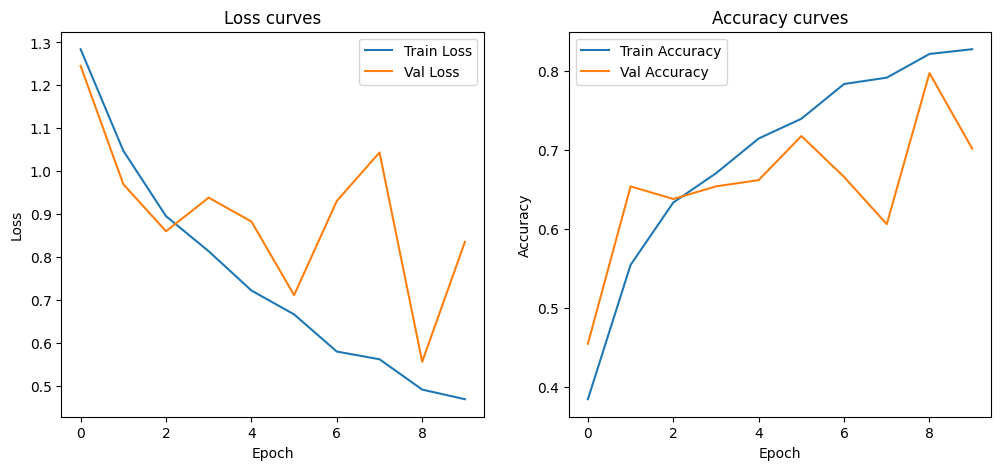

In [17]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from pathlib import Path
import pandas as pd

# 1. Rebuild df if missing by looking at the dataset directories
if 'df' not in globals() or df is None or df.empty:
    print("Rebuilding dataframe from dataset folders...")
    all_labels_dir = Path("animal-dataset/dataset/all_labels")

    # If all_labels is empty or doesn't exist, we can reconstruct from original training/testing structure
    # or if files are already renamed inside 'all_labels', let's check if we need to regenerate.
    # A reliable way is to scan original directories and move them if they are still there,
    # or build the dataframe directly from whatever is in 'all_labels' if we kept track.
    # Since uuid.uuid4() names lose label context, let's re-run a quick reconstruction from
    # original directories if they exist, or fallback to rebuilding the mapping.

    train_dir = 'animal-dataset/dataset/Training'
    test_dir = 'animal-dataset/dataset/Testing'
    categories = ['crows', 'bears', 'rats', 'elephants']

    rows = []
    # Scan all_labels files
    if all_labels_dir.exists() and len(os.listdir(all_labels_dir)) > 0:
        # Since we renamed files with random uuids, we can scan the original folders
        # to find if files still exist there, or check our current all_labels.
        # If the user already ran the moving cells in a previous session, original directories might be empty.
        # Let's check original dirs first.
        originals_exist = False
        for cat in categories:
            p_tr = Path(train_dir) / cat
            p_te = Path(test_dir) / cat
            if (p_tr.exists() and len(os.listdir(p_tr)) > 0) or (p_te.exists() and len(os.listdir(p_te)) > 0):
                originals_exist = True
                break

        if originals_exist:
            print("Original directories still contain files. Re-running mover_renamer logic...")
            subfolder_path = all_labels_dir
            import uuid
            import shutil
            df = pd.DataFrame(columns=['file_path', 'label'])
            def mover_renamer_local(directory):
                global df
                new_rows = []
                dir_path = Path(directory)
                label_name = dir_path.name
                if dir_path.exists():
                    for file in dir_path.iterdir():
                        if file.is_file() and not file.name.endswith("_gs") and "_gs" not in file.name:
                            extension = file.suffix
                            new_filename = f"{uuid.uuid4().hex}{extension}"
                            new_path = subfolder_path / new_filename
                            shutil.move(str(file), str(new_path))
                            new_rows.append({'file_path': str(new_path), 'label': label_name})
                if new_rows:
                    df = pd.concat([df, pd.DataFrame(new_rows)], ignore_index=True)

            for cat in categories:
                mover_renamer_local(f"animal-dataset/dataset/Training/{cat}")
                mover_renamer_local(f"animal-dataset/dataset/Testing/{cat}")
        else:
            print("Original directories are empty. Inferring labels from existing files in all_labels...")
            # If original directories are empty, files are already in all_labels.
            # To map them back without losing labels, we can check if there are any remaining files or
            # if we have to re-download. If we can't infer, we re-extract from zip directly to be 100% safe.
            import zipfile
            print("Re-extracting dataset from zip to clean state to guarantee correct labels...")
            zip_path = "./animal-dataset.zip"
            if Path(zip_path).exists():
                with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                    zip_ref.extractall("./animal-dataset-temp")
                # Now we have a clean source to build our df
                df = pd.DataFrame(columns=['file_path', 'label'])
                subfolder_path = Path("animal-dataset/dataset/all_labels")
                subfolder_path.mkdir(parents=True, exist_ok=True)
                import uuid
                import shutil
                def mover_renamer_temp(directory):
                    global df
                    new_rows = []
                    dir_path = Path(directory)
                    label_name = dir_path.name
                    if dir_path.exists():
                        for file in dir_path.iterdir():
                            if file.is_file():
                                extension = file.suffix
                                new_filename = f"{uuid.uuid4().hex}{extension}"
                                new_path = subfolder_path / new_filename
                                shutil.copy(str(file), str(new_path))
                                new_rows.append({'file_path': str(new_path), 'label': label_name})
                    if new_rows:
                        df = pd.concat([df, pd.DataFrame(new_rows)], ignore_index=True)

                for cat in categories:
                    mover_renamer_temp(f"./animal-dataset-temp/dataset/Training/{cat}")
                    mover_renamer_temp(f"./animal-dataset-temp/dataset/Testing/{cat}")
                # Clean up temp extraction
                shutil.rmtree("./animal-dataset-temp")

# 2. Establish train/val split and generating grayscale file paths
print("Generating splits and preparing grayscale datasets...")
random_seed = 42
X = df['file_path']
y = df['label']

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=random_seed, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=random_seed, stratify=y_train_full
)

def convert_to_grayscale(path_str):
    path = Path(path_str)
    new_filename = f"{path.stem}_gs{path.suffix}"
    new_path = path.parent / new_filename
    if not new_path.exists():
        with Image.open(path) as img:
            gs_img = img.convert("L")
            gs_img.save(new_path)
    return str(new_path)

X_train_gs = X_train.apply(convert_to_grayscale)
X_val_gs = X_val.apply(convert_to_grayscale)
X_test_gs = X_test.apply(convert_to_grayscale)

# 3. Map target labels to numerical values
label_to_idx = {'crows': 0, 'bears': 1, 'rats': 2, 'elephants': 3}
y_train_idx = y_train.map(label_to_idx).values
y_val_idx = y_val.map(label_to_idx).values

# 4. Custom Dataset
class AnimalDataset(Dataset):
    def __init__(self, file_paths, labels, transform=None):
        self.file_paths = list(file_paths)
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img_path = self.file_paths[idx]
        image = Image.open(img_path).convert('L')
        label = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        return image, label

# 5. Define transformations
train_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

val_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# 6. Instantiate Datasets and DataLoaders
train_dataset = AnimalDataset(X_train_gs, y_train_idx, transform=train_transforms)
val_dataset = AnimalDataset(X_val_gs, y_val_idx, transform=val_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# 7. Device Setup, Model, Optimizer, Loss Function
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = SimpleCNN(in_channels=1, num_classes=4).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 8. Training Loop
epochs = 10
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device, dtype=torch.long)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_acc = correct_train / total_train

    # Validation phase
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device, dtype=torch.long)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_val_acc = correct_val / total_val

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accs.append(epoch_train_acc)
    val_accs.append(epoch_val_acc)

    print(f"Epoch [{epoch+1}/{epochs}] - "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")

# 9. Plotting Performance
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.title('Loss curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Accuracy')
plt.plot(val_accs, label='Val Accuracy')
plt.title('Accuracy curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()